In [1]:
import yaml  
from pymilvus import MilvusClient
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
print(PROJECT_ROOT)
sys.path.append(PROJECT_ROOT)

c:\Users\hieuvt.ctv\code\beeflow


In [2]:
config_path = "../../config/milvus.yaml"
with open(config_path, "r", encoding="utf-8") as f:
        default_config = yaml.safe_load(f)

print(default_config)
client = MilvusClient(uri= default_config["uri"], user= default_config["username"], password = default_config["password"], db_name= default_config["db_name"])


{'alias': 'default', 'uri': 'http://10.216.66.53:19530', 'db_name': 'ai_nlp_db', 'username': 'ai_nlp_user', 'password': 'Milvus@123', 'connection_pool_size': 100, 'enable_ssl': False, 'timeout': 10.0, 'index_params': {'index_type': 'IVF_FLAT', 'metric_type': 'COSINE', 'params': {'nlist': 1024}}, 'search_params': {'nprobe': 10}}


In [4]:
import pandas as pd 
def load_all_embeddings_to_df(
    client: MilvusClient,
    collection_name: str,
    partition_names: list[str] = ["document"],
    batch_size: int = 1000,
) -> pd.DataFrame:
    """
    Load all vectors + topics from a Milvus collection into a DataFrame.

    Returns:
        DataFrame with columns:
            - vector: List[float]
            - topic:  str
    """
    all_ids = []
    all_vectors = []
    all_topics = []

    offset = 0
    while True:
        res = client.query(
            collection_name=collection_name,
            partition_names= partition_names,
            filter= "",
            output_fields=["vector", "topic", "chunk_id"],
            limit=batch_size,
            offset=offset
        )

        if not res:
            break

        for r in res:
            all_ids.append(r["chunk_id"])
            all_vectors.append(r["vector"])
            all_topics.append(r["topic"])

        offset += batch_size

    df = pd.DataFrame({
        "id": all_ids,
        "vector": all_vectors,
        "topic": all_topics
    })
    return df 


In [5]:
collection_name = "bot_a6cb68dd_b472_4183_ad26_d406c5c3b841"
df = load_all_embeddings_to_df(client, collection_name)

In [6]:
df.head()

,id,vector,topic
0,00188c29-7b7d-4e04-9a7a-2626f0badbe1,"[0.011226589791476727, -0.0368560254573822, -0...",sản-phẩm/khcn/the
1,00741563-735c-4075-9685-44654684ee44,"[-0.03766665980219841, -0.011572287417948246, ...",sản-phẩm/khdn/ngân-hàng-điện-tử
2,0079511f-4c47-4fc5-a4c6-1eac041d3a4b,"[-0.044274259358644485, -0.03583375737071037, ...",sản-phẩm/khcn/the
3,007f71a6-792a-4eb8-b347-a94f0ed0cde4,"[-0.025340639054775238, 0.001430789940059185, ...",Lãi-suất-biểu-phí
4,00bb957d-92ea-4e54-a4d5-5fe6ef342119,"[-0.024486294016242027, 0.00014227500651031733...",sản-phẩm/khcn/the


# Centroid 

In [7]:
import numpy as np
from collections import defaultdict

topic_vectors = defaultdict(list)

for _, row in df.iterrows():
    topic_vectors[row["topic"]].append(row["vector"])

topic_centroids = {
    topic: np.mean(np.vstack(vectors), axis=0)
    for topic, vectors in topic_vectors.items()
}

# PCA

In [9]:
import numpy as np

X = np.vstack(df["vector"].values)

topics = df["topic"].values

print("Shape:", X.shape)  # (num_docs, embedding_dim)

Shape: (2120, 1024)


In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.06171475 0.04888205]
Total explained variance: 0.11059680709233777


In [11]:
topic_names = list(topic_centroids.keys())
centroid_matrix = np.vstack([topic_centroids[t] for t in topic_names])

centroids_pca = pca.transform(centroid_matrix)

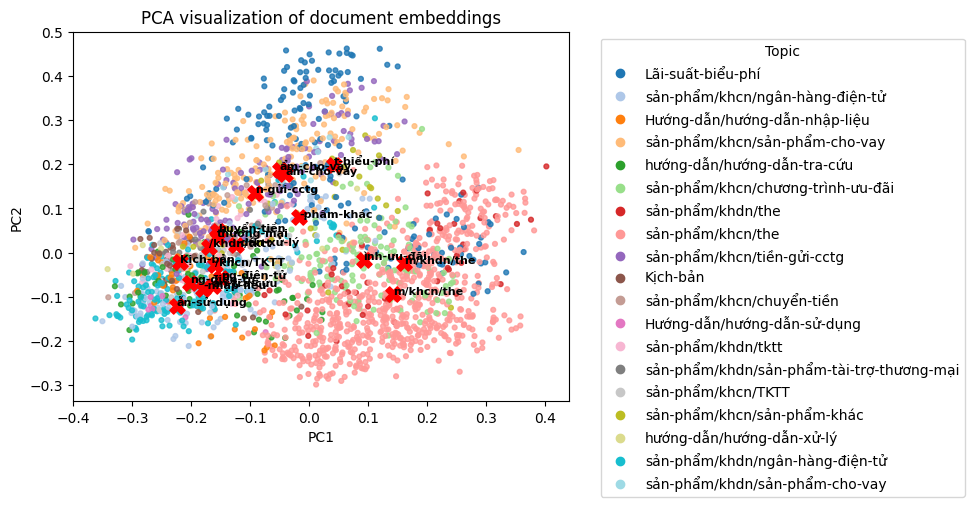

<Figure size 3000x2000 with 0 Axes>

In [12]:
import matplotlib.pyplot as plt 
unique_topics = list(set(topics))
topic_to_id = {t: i for i, t in enumerate(unique_topics)}
colors = [topic_to_id[t] for t in topics]

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=colors,
    cmap="tab20",
    s=12,
    alpha=0.8
)


centroid_colors = [topic_to_id[t] for t in topic_names]
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c= 'red',
    s=120,
    marker="X",
    label="Topic centroid"
)

for i, topic in enumerate(topic_names):
    plt.text(
        centroids_pca[i, 0],
        centroids_pca[i, 1],
        topic[-10:],
        fontsize=8,
        weight="bold"
    )

plt.title("PCA visualization of document embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")

handles = [
    plt.Line2D([], [], marker="o", linestyle="", color=scatter.cmap(scatter.norm(i)))
    for i in range(len(unique_topics))
]
plt.legend(
    handles,
    unique_topics,
    title="Topic",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.figure(figsize= (30, 20))
plt.tight_layout()
plt.show()

# UMAP 

In [13]:
import umap

reducer = umap.UMAP(
    n_neighbors=15,      # 10–30 là hợp lý
    min_dist=0.1,        # nhỏ → cluster chặt hơn
    n_components=2,
    metric="cosine",     # RẤT QUAN TRỌNG cho embedding NLP
    random_state=42
)

X_umap = reducer.fit_transform(X)

c:\Users\hieuvt.ctv\AppData\Local\anaconda3\envs\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\hieuvt.ctv\AppData\Local\anaconda3\envs\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [14]:
centroids_umap = reducer.transform(centroid_matrix)

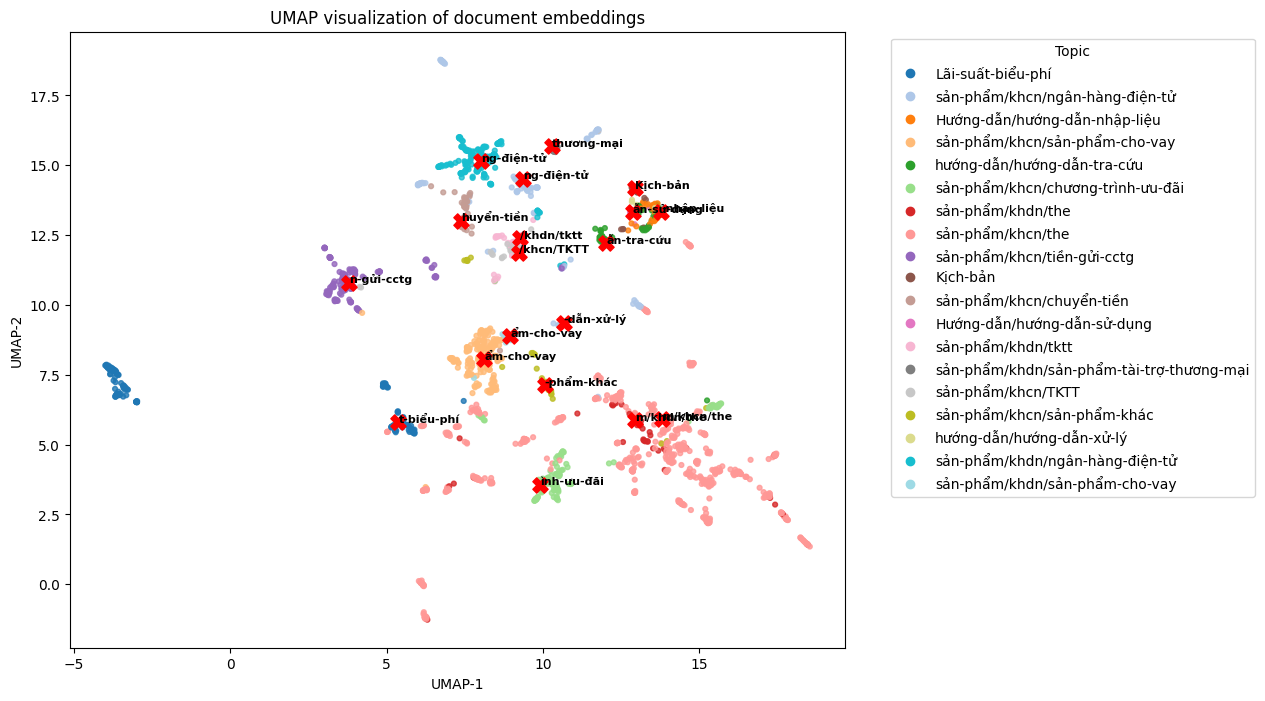

<Figure size 2000x1000 with 0 Axes>

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# map topic -> color id
unique_topics = list(set(topics))
topic_to_id = {t: i for i, t in enumerate(unique_topics)}
colors = [topic_to_id[t] for t in topics]

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=colors,
    cmap="tab20",
    s=12,
    alpha=0.8
)

centroid_colors = [topic_to_id[t] for t in topic_names]
plt.scatter(
    centroids_umap[:, 0],
    centroids_umap[:, 1],
    # c= centroid_colors,
    c= 'red',
    s=120,
    marker="X",
    label="Topic centroid"
)

# annotate topic name
for i, topic in enumerate(topic_names):
    plt.text(
        centroids_umap[i, 0],
        centroids_umap[i, 1],
        topic[-10:],
        fontsize=8,
        weight="bold"
    )

plt.title("UMAP visualization of document embeddings")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")

# legend
handles = [
    plt.Line2D([], [], marker="o", linestyle="", 
               color=scatter.cmap(scatter.norm(i)))
    for i in range(len(unique_topics))
]

plt.legend(
    handles,
    unique_topics,
    title="Topic",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.figure(figsize=(20, 10))
plt.tight_layout()
plt.show()


# Miss classification 

In [ ]:
from beegen.storage import mongo
from beegen.storage.mongo.mongo_engine import AsyncMongoEngine
import datetime
import json
import asyncio
from pymongo import ASCENDING, DESCENDING, InsertOne, UpdateOne, DeleteOne, ReplaceOne
from beegen.configs import MongoOperation, MongoConfig
import yaml

class MongoNode():
    def __init__(self):
        
        with open("../../config/beeflow.yaml", "r", encoding="utf-8") as f:
            default_config = yaml.safe_load(f)
        config = MongoConfig(authen_source= default_config["authen_source"], uri= default_config["uri"])
        self.executor = AsyncMongoEngine(
            config= config
        )


        self.mem = dict()


    async def search_chunk(self, chunk_id: str, collection_name: str= "chunk_data"):
        result = await self.executor.run(
            MongoOperation.FIND_ONE,
            {
                "collection_name": collection_name,
                "query": {
                    "chunk_id": chunk_id
                }
            }
        )

        return result["data"]["raw_text"]

In [35]:
from typing import Dict, List
from sklearn.metrics.pairwise import cosine_distances

def compute_misclassification(
    df,
    topic_centroids: Dict[str, List[float]],
    top_k: int = 1
) -> List[str]:
    """
    Args:
        df: pandas DataFrame with columns [id, vector, topic]
        topic_centroids: {topic: centroid_vector}
        top_k: number of nearest centroids to consider

    Returns:
        List of document ids that are misclassified
    """

    # prepare centroid matrix
    centroid_topics = list(topic_centroids.keys())
    centroid_matrix = np.vstack(
        [topic_centroids[t] for t in centroid_topics]
    )

    misclassified_ids = []

    for row in df.itertuples(index=False):
        vec = np.array(row.vector).reshape(1, -1)
        true_topic = row.topic

        # compute cosine distance to all centroids
        distances = cosine_distances(vec, centroid_matrix)[0]

        # get top_k nearest centroid indices
        nearest_idx = np.argsort(distances)[:top_k]
        nearest_topics = {centroid_topics[i] for i in nearest_idx}

        # check misclassification
        if true_topic not in nearest_topics:
            misclassified_ids.append((row.id, row.topic, nearest_topics))

    # compute misclassification rate
    mis_rate = len(misclassified_ids) / len(df) * 100

    print(f"Misclassification rate: {mis_rate:.2f}% "
          f"({len(misclassified_ids)}/{len(df)})")

    return misclassified_ids

In [42]:
mis_ids = compute_misclassification(
    df=df,
    topic_centroids=topic_centroids,
    top_k=5
)

print("Misclassified IDs:", mis_ids[:10])

Misclassification rate: 0.33% (7/2120)
Misclassified IDs: [('29c844da-849d-4043-919e-6c6e9cd2904f', 'sản-phẩm/khcn/ngân-hàng-điện-tử', {'sản-phẩm/khcn/TKTT', 'sản-phẩm/khcn/sản-phẩm-cho-vay', 'sản-phẩm/khcn/tiền-gửi-cctg', 'sản-phẩm/khdn/tktt', 'hướng-dẫn/hướng-dẫn-tra-cứu'}), ('3e884e94-c50f-4c29-8e9c-8f1aacbd576b', 'sản-phẩm/khdn/ngân-hàng-điện-tử', {'sản-phẩm/khcn/ngân-hàng-điện-tử', 'Lãi-suất-biểu-phí', 'sản-phẩm/khcn/sản-phẩm-cho-vay', 'sản-phẩm/khdn/the', 'hướng-dẫn/hướng-dẫn-tra-cứu'}), ('54be355a-4531-48d2-a74f-006ccbe1cc5d', 'sản-phẩm/khcn/the', {'sản-phẩm/khcn/ngân-hàng-điện-tử', 'Kịch-bản', 'hướng-dẫn/hướng-dẫn-xử-lý', 'Hướng-dẫn/hướng-dẫn-nhập-liệu', 'hướng-dẫn/hướng-dẫn-tra-cứu'}), ('7ce69bea-2eba-4297-9ed7-d919771699e1', 'sản-phẩm/khcn/ngân-hàng-điện-tử', {'Lãi-suất-biểu-phí', 'sản-phẩm/khcn/the', 'sản-phẩm/khcn/chương-trình-ưu-đãi', 'hướng-dẫn/hướng-dẫn-xử-lý', 'sản-phẩm/khcn/tiền-gửi-cctg'}), ('a63709b0-bd78-418a-a809-bb024063cf87', 'sản-phẩm/khcn/chương-trình-ưu-đãi', 

In [43]:
mongo_client = MongoNode() 
for id in mis_ids: 
    chunk = await mongo_client.search_chunk(id[0])
    print(chunk)
    print(f"True Topic: {id[1]}")
    print(f"nearest topics: {id[2]}")
    print("_" * 30)


42. SMS Banking
2. Điều kiện và đối tượng sử dụng
KHCN, KHDN có TKTT và đăng ký sử dụng dịch vụ.

True Topic: sản-phẩm/khcn/ngân-hàng-điện-tử
nearest topics: {'sản-phẩm/khcn/TKTT', 'sản-phẩm/khcn/sản-phẩm-cho-vay', 'sản-phẩm/khcn/tiền-gửi-cctg', 'sản-phẩm/khdn/tktt', 'hướng-dẫn/hướng-dẫn-tra-cứu'}
______________________________
128. SMS BANKING dành cho KH doanh nghiệp
Phí dịch vụ SMS Banking KHDN
Phí dịch vụ: 220.000 VNĐ/ năm (đã bao gồm VAT)
(Trường hợp KH đăng ký theo gói combo, HD KH liên hệ RM quản lý để được tư vấn phí)
Kỳ thu phí: 1 năm thu 1 lần và thu đầu kỳ

True Topic: sản-phẩm/khdn/ngân-hàng-điện-tử
nearest topics: {'sản-phẩm/khcn/ngân-hàng-điện-tử', 'Lãi-suất-biểu-phí', 'sản-phẩm/khcn/sản-phẩm-cho-vay', 'sản-phẩm/khdn/the', 'hướng-dẫn/hướng-dẫn-tra-cứu'}
______________________________
105. Sản phẩm QR trả sau
10. Kênh đóng/hủy dịch vụ
Thực hiện tại CN/PGD MB
(Trường hợp KH được tặng QR trả sau nhưng không đồng ý nhận, yêu cầu hủy dịch vụ, tiếp nhận thông tin chuyển tuyến 2